# House Price Prediction (v1)
**CSE422: Artificial Intelligence, BRAC University, Spring 2024.** Faiaz Abrar Zaman Pronoy, Sinthia Khandoker and Md. Jahirul Islam Zishan.

The original course submission: data cleaning, encoding, and three regression models.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import StandardScaler, RobustScaler

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn import neighbors
from math import sqrt

from sklearn.tree import export_graphviz
import graphviz
from IPython.display import display

In [ ]:
housing = pd.read_csv('data/house_prices.csv')
housing2 = pd.read_csv('data/house_prices.csv')
housing.head(10)

,Id,LotArea,Street,Alley,Utilities,Neighborhood,BldgType,HouseStyle,YearBuilt,RoofStyle,Foundation,Electrical,GrLivArea,FullBath,BedroomAbvGr,KitchenAbvGr,Fireplaces,GarageCars,SaleCondition,SalePrice
0,1,8450.0,Pave,NaN,AllPub,CollgCr,1Fam,2Story,2003.0,Gable,PConc,SBrkr,1710.0,2.0,3.0,1.0,0.0,2.0,Normal,208500
1,2,9600.0,Pave,NaN,AllPub,Veenker,1Fam,1Story,1976.0,Gable,CBlock,SBrkr,1262.0,2.0,3.0,1.0,1.0,2.0,Normal,181500
2,3,11250.0,Pave,NaN,AllPub,CollgCr,1Fam,2Story,2001.0,Gable,PConc,SBrkr,1786.0,2.0,3.0,1.0,1.0,2.0,Normal,223500
3,4,9550.0,Pave,NaN,AllPub,Crawfor,1Fam,2Story,1915.0,Gable,BrkTil,SBrkr,1717.0,1.0,3.0,1.0,1.0,3.0,Abnorml,140000
4,5,14260.0,Pave,NaN,AllPub,NoRidge,1Fam,2Story,2000.0,Gable,PConc,SBrkr,2198.0,2.0,4.0,1.0,1.0,3.0,Normal,250000
5,6,14115.0,Pave,NaN,AllPub,Mitchel,1Fam,1.5Fin,1993.0,Gable,Wood,SBrkr,1362.0,1.0,1.0,1.0,0.0,2.0,Normal,143000
6,7,10084.0,Pave,NaN,AllPub,Somerst,1Fam,1Story,2004.0,Gable,PConc,SBrkr,1694.0,2.0,3.0,1.0,1.0,2.0,Normal,307000
7,8,10382.0,Pave,NaN,AllPub,NWAmes,1Fam,2Story,1973.0,Gable,CBlock,SBrkr,2090.0,2.0,3.0,1.0,2.0,2.0,Normal,200000
8,9,6120.0,Pave,NaN,AllPub,OldTown,1Fam,1.5Fin,1931.0,Gable,BrkTil,FuseF,1774.0,2.0,2.0,2.0,2.0,2.0,Abnorml,129900
9,10,7420.0,Pave,NaN,AllPub,BrkSide,2fmCon,1.5Unf,1939.0,Gable,BrkTil,SBrkr,1077.0,1.0,2.0,2.0,2.0,1.0,Normal,118000


In [ ]:
housing.shape

(1460, 20)

### Checking for missing values

In [ ]:
housing.isnull()

,Id,LotArea,Street,Alley,Utilities,Neighborhood,BldgType,HouseStyle,YearBuilt,RoofStyle,Foundation,Electrical,GrLivArea,FullBath,BedroomAbvGr,KitchenAbvGr,Fireplaces,GarageCars,SaleCondition,SalePrice
0,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1456,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1457,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1458,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


### Missing values in each column

In [ ]:
housing.isnull().sum()

Id                  0
LotArea             1
Street              0
Alley            1369
Utilities          12
Neighborhood        7
BldgType           11
HouseStyle          6
YearBuilt           7
RoofStyle           6
Foundation          8
Electrical         13
GrLivArea          15
FullBath            6
BedroomAbvGr        8
KitchenAbvGr        5
Fireplaces          4
GarageCars          4
SaleCondition       1
SalePrice           0
dtype: int64

### Dropping Alley and Id: Alley is more than 50% empty and Id has no link with the price

In [ ]:
housing.drop(['Alley'], axis=1, inplace=True)
housing.drop(['Id'], axis=1, inplace=True)

housing.shape

(1460, 18)

In [ ]:
housing.isnull().sum()

LotArea           1
Street            0
Utilities        12
Neighborhood      7
BldgType         11
HouseStyle        6
YearBuilt         7
RoofStyle         6
Foundation        8
Electrical       13
GrLivArea        15
FullBath          6
BedroomAbvGr      8
KitchenAbvGr      5
Fireplaces        4
GarageCars        4
SaleCondition     1
SalePrice         0
dtype: int64

array([[<Axes: title={'center': 'LotArea'}>,
        <Axes: title={'center': 'YearBuilt'}>,
        <Axes: title={'center': 'GrLivArea'}>],
       [<Axes: title={'center': 'FullBath'}>,
        <Axes: title={'center': 'BedroomAbvGr'}>,
        <Axes: title={'center': 'KitchenAbvGr'}>],
       [<Axes: title={'center': 'Fireplaces'}>,
        <Axes: title={'center': 'GarageCars'}>,
        <Axes: title={'center': 'SalePrice'}>]], dtype=object)

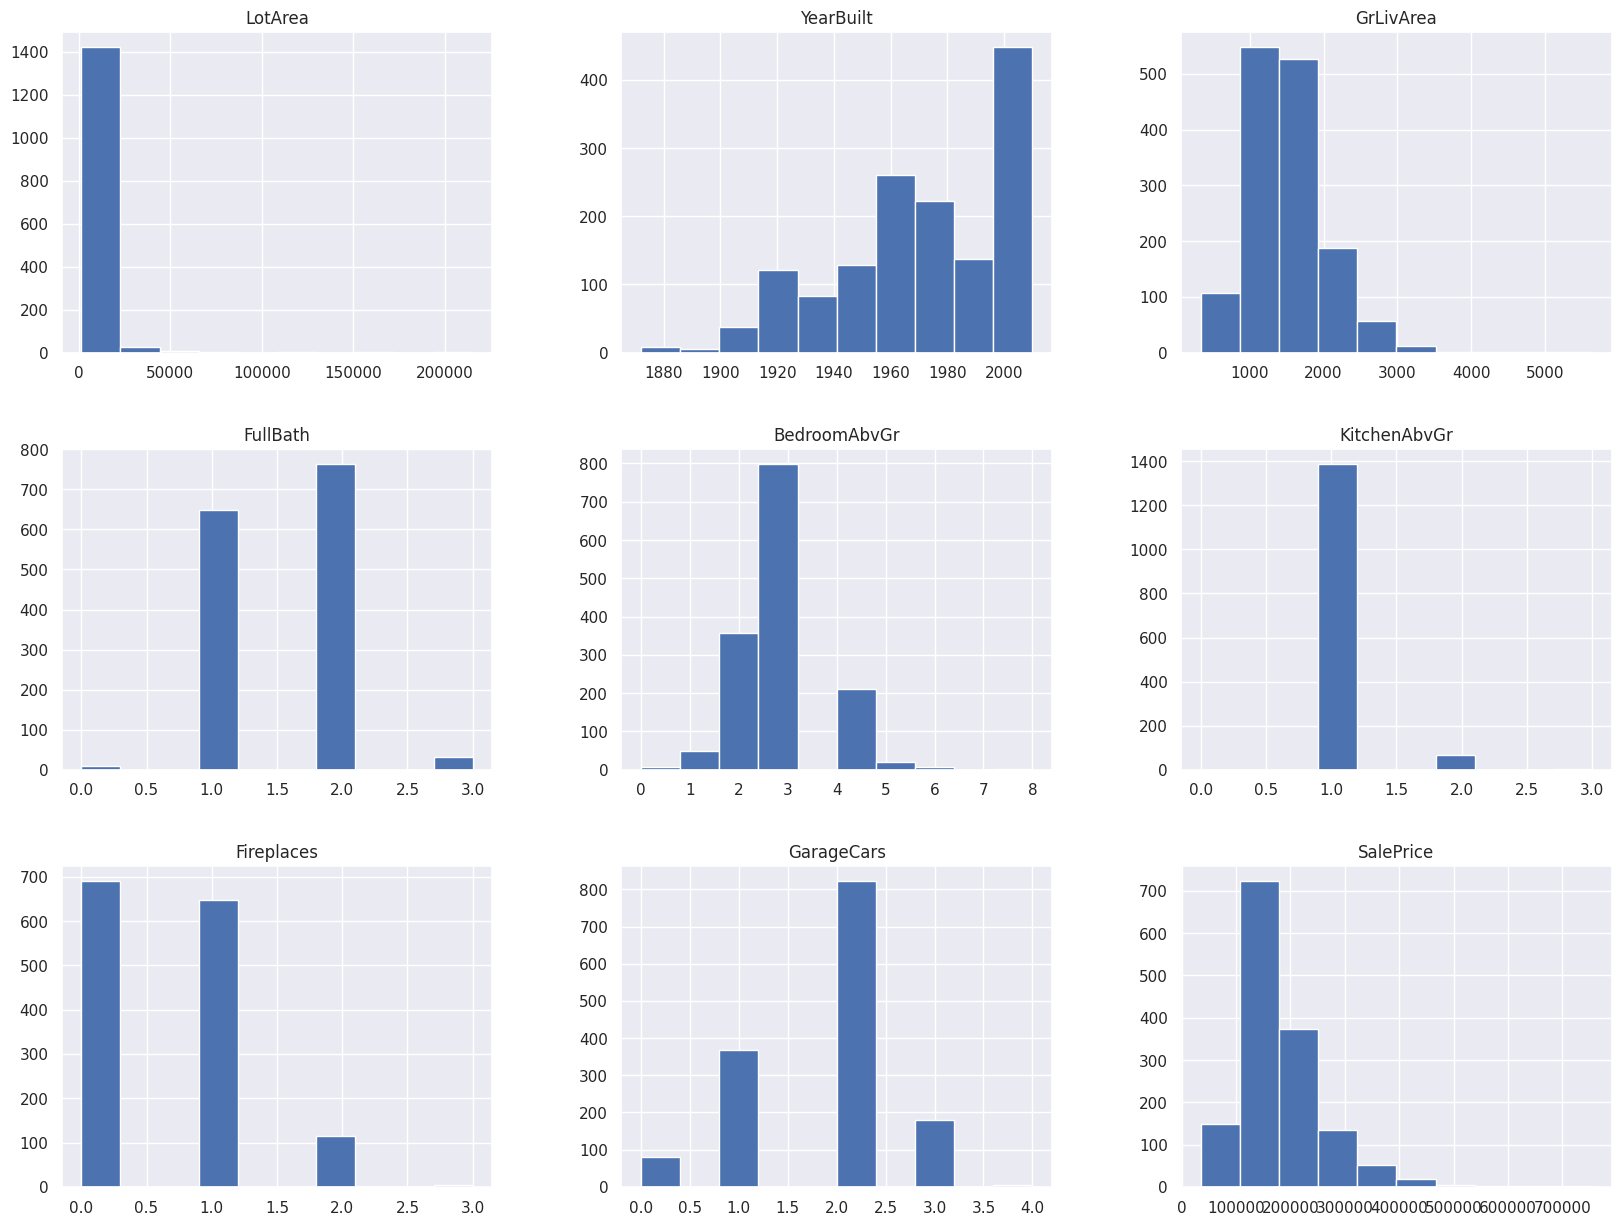

In [ ]:
%matplotlib inline

housing.hist(bins=10,figsize=(20,15))

### Replacing missing numeric values with the mean

In [ ]:
housing['LotArea'] = housing['LotArea'].fillna(housing['LotArea'].mean())
housing['YearBuilt'] = housing['YearBuilt'].fillna(housing['YearBuilt'].mean())
housing['GrLivArea'] = housing['GrLivArea'].fillna(housing['GrLivArea'].mean())
housing['FullBath'] = housing['FullBath'].fillna(housing['FullBath'].mean())
housing['BedroomAbvGr'] = housing['BedroomAbvGr'].fillna(housing['BedroomAbvGr'].mean())
housing['KitchenAbvGr'] = housing['KitchenAbvGr'].fillna(housing['KitchenAbvGr'].mean())
housing['Fireplaces'] = housing['Fireplaces'].fillna(housing['Fireplaces'].mean())
housing['GarageCars'] = housing['GarageCars'].fillna(housing['GarageCars'].mean())

In [ ]:
housing.isnull().sum()

LotArea           0
Street            0
Utilities        12
Neighborhood      7
BldgType         11
HouseStyle        6
YearBuilt         0
RoofStyle         6
Foundation        8
Electrical       13
GrLivArea         0
FullBath          0
BedroomAbvGr      0
KitchenAbvGr      0
Fireplaces        0
GarageCars        0
SaleCondition     1
SalePrice         0
dtype: int64

### Replacing missing categorical values with the mode (most frequent value)

In [ ]:
housing['Utilities'] = housing['Utilities'].fillna(housing['Utilities'].mode()[0])
housing['Neighborhood'] = housing['Neighborhood'].fillna(housing['Neighborhood'].mode()[0])
housing['BldgType'] = housing['BldgType'].fillna(housing['BldgType'].mode()[0])
housing['HouseStyle'] = housing['HouseStyle'].fillna(housing['HouseStyle'].mode()[0])
housing['RoofStyle'] = housing['RoofStyle'].fillna(housing['RoofStyle'].mode()[0])
housing['Foundation'] = housing['Foundation'].fillna(housing['Foundation'].mode()[0])
housing['Electrical'] = housing['Electrical'].fillna(housing['Electrical'].mode()[0])
housing['SaleCondition'] = housing['SaleCondition'].fillna(housing['SaleCondition'].mode()[0])

In [ ]:
housing.isnull().sum()

LotArea          0
Street           0
Utilities        0
Neighborhood     0
BldgType         0
HouseStyle       0
YearBuilt        0
RoofStyle        0
Foundation       0
Electrical       0
GrLivArea        0
FullBath         0
BedroomAbvGr     0
KitchenAbvGr     0
Fireplaces       0
GarageCars       0
SaleCondition    0
SalePrice        0
dtype: int64

### Checking for negative values in the numeric features

In [ ]:
float_columns = ['LotArea', 'YearBuilt', 'GrLivArea', 'FullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'Fireplaces', 'GarageCars', 'SalePrice']

for column in float_columns:
    if (housing[column] < 0).any():
        print(f"{column} column has negative values \n ")
    else:
        print(f"{column} column does not have negative values \n ")

LotArea column does not have negative values 
 
YearBuilt column does not have negative values 
 
GrLivArea column does not have negative values 
 
FullBath column does not have negative values 
 
BedroomAbvGr column does not have negative values 
 
KitchenAbvGr column does not have negative values 
 
Fireplaces column does not have negative values 
 
GarageCars column does not have negative values 
 
SalePrice column does not have negative values 
 


### Checking for an imbalanced dataset

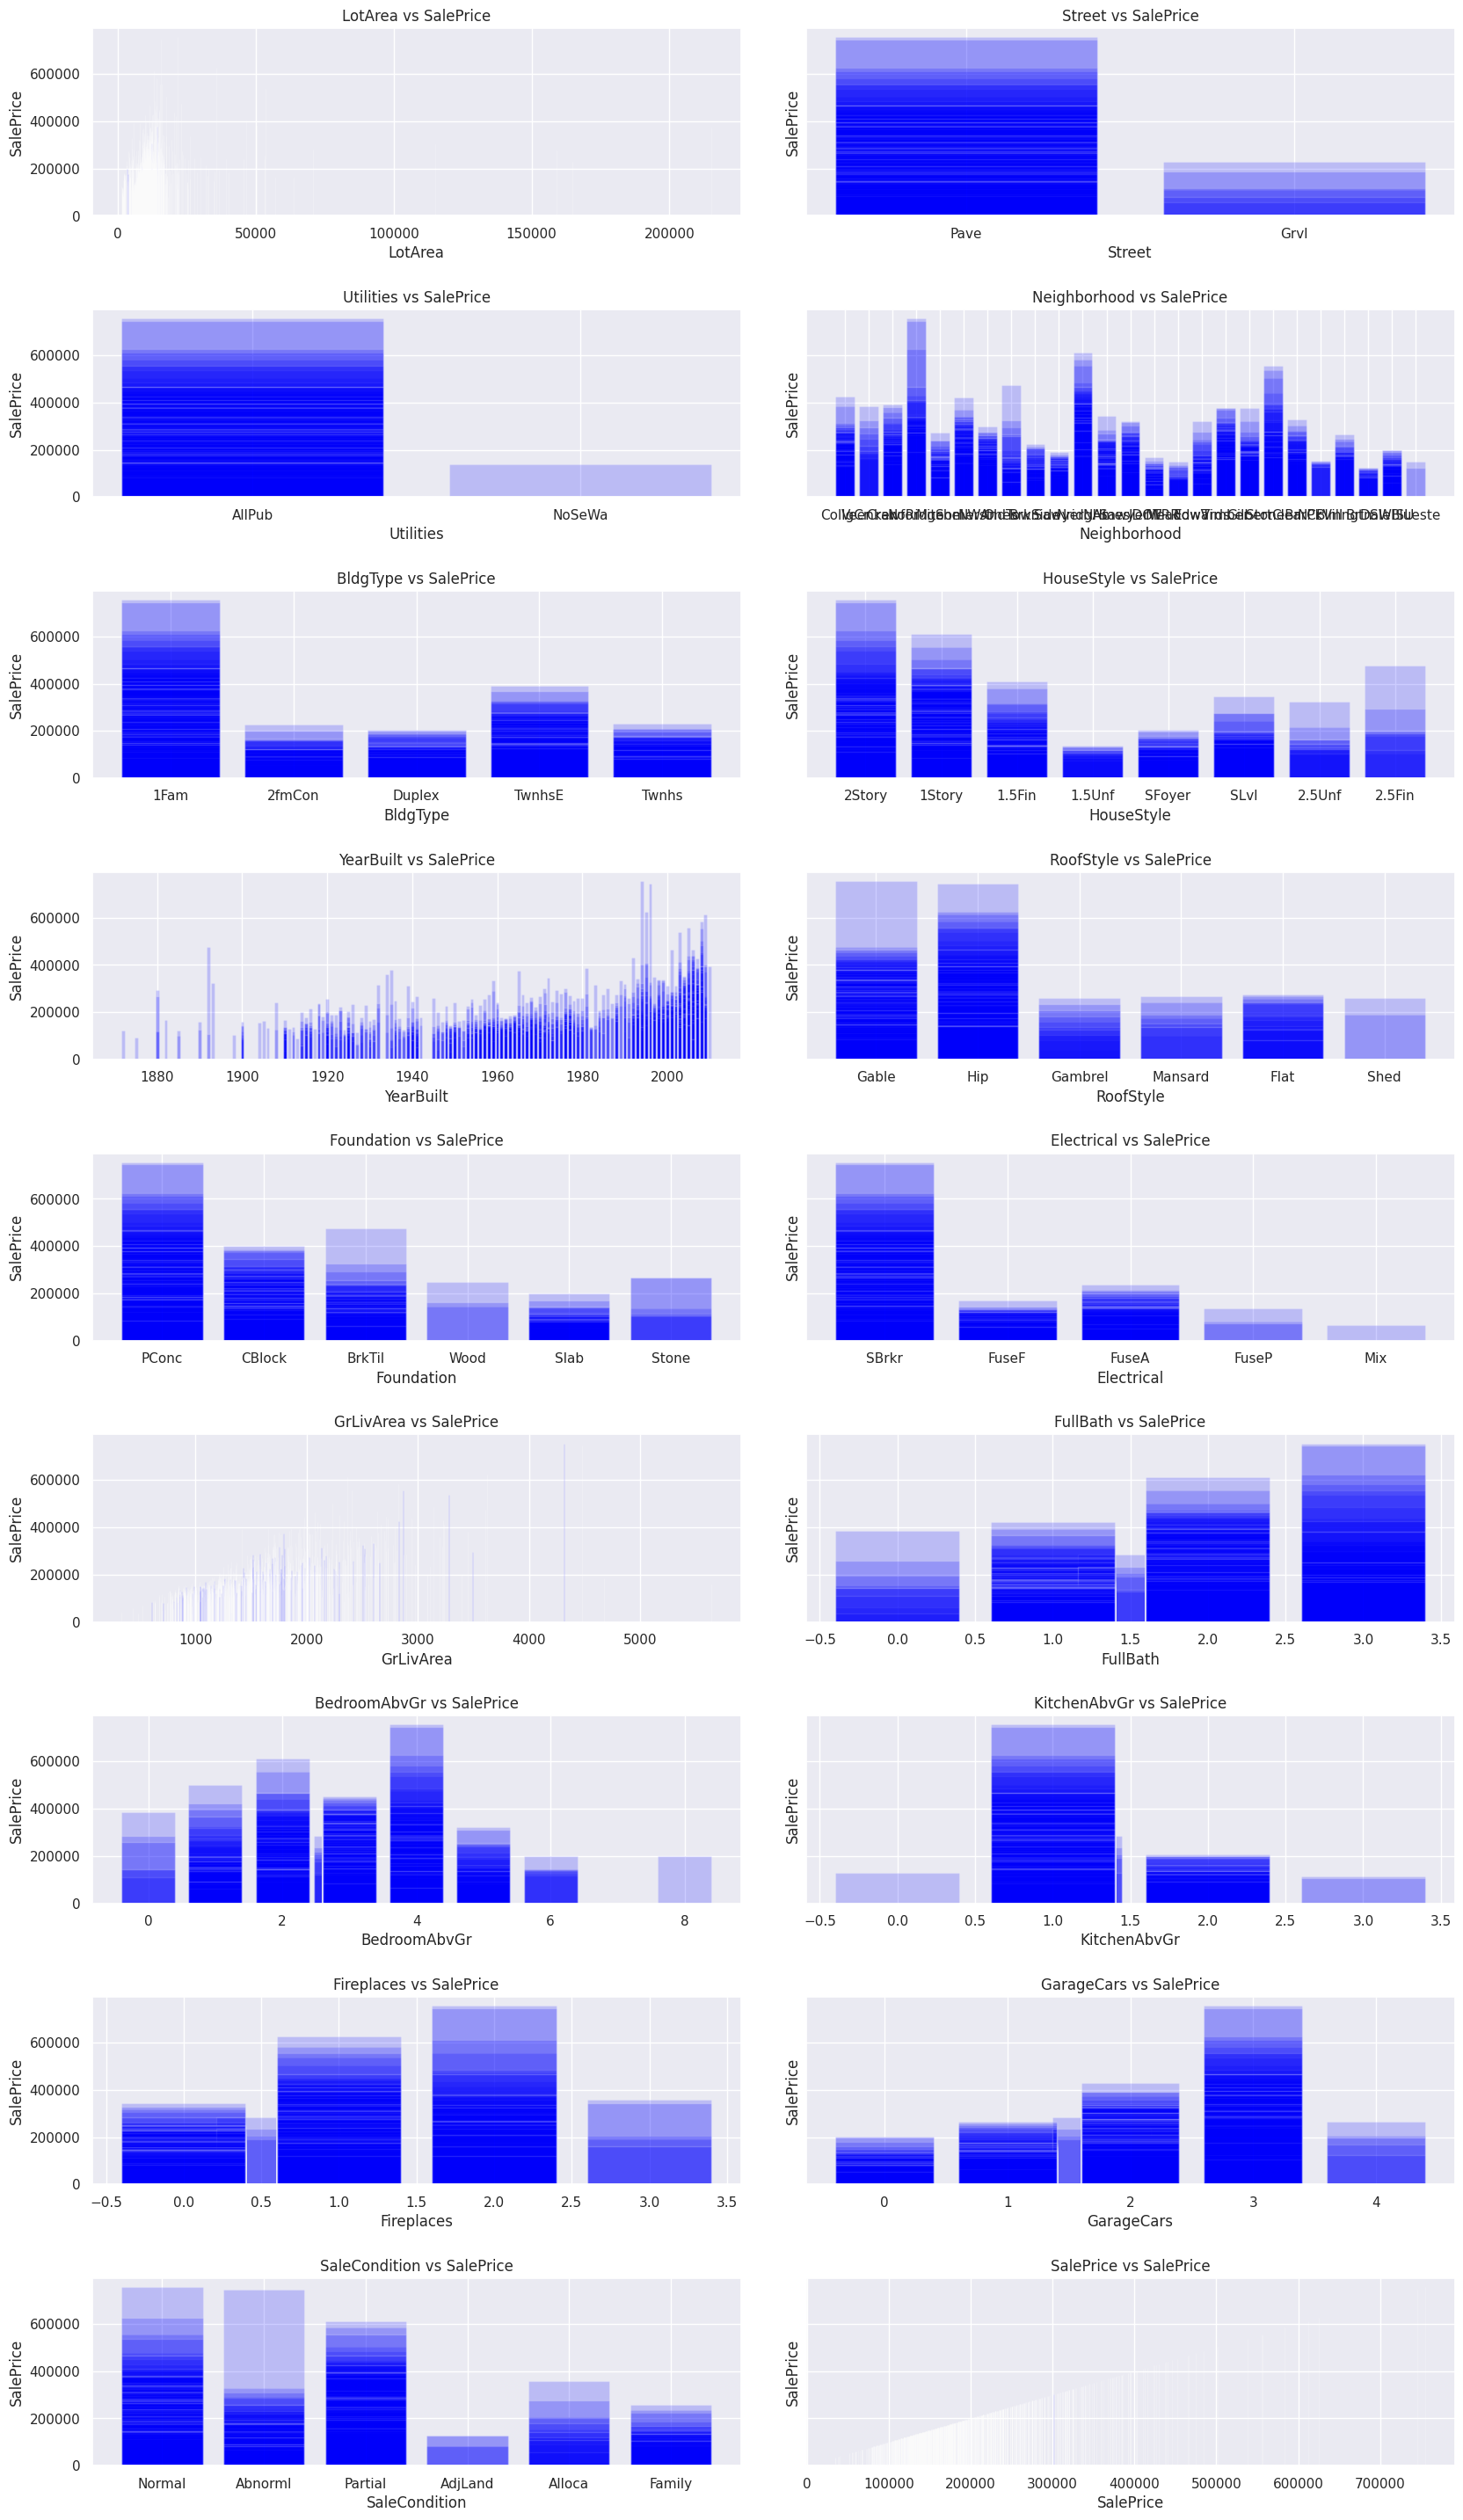

In [ ]:
columns_to_plot = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
target = "SalePrice"

figure, axs = plt.subplots(len(columns_to_plot) // 2 + len(columns_to_plot) %
                        2, 2, figsize=(20, len(columns_to_plot) * 2), sharey=True, squeeze=True)

for i, column in enumerate(columns_to_plot):
    axs[i // 2, i % 2].bar(housing.iloc[:, column], housing[target], color='Blue', alpha=0.2)
    axs[i // 2, i % 2].set_xlabel(housing.columns[column])
    axs[i // 2, i % 2].set_ylabel(target)
    axs[i // 2, i % 2].set_title(f'{housing.columns[column]} vs {target}')

figure.subplots_adjust(wspace=0.1, hspace=0.5)

plt.show()

### Comparing the cleaned data with the raw data

In [ ]:
NULL_values_comparison = pd.concat([housing2.isnull().sum(), housing.isnull().sum()], axis=1)
NULL_values_comparison.columns = ['NULL_Values_housing2', 'NULL_Values_housing']

print(NULL_values_comparison)

               NULL_Values_housing2  NULL_Values_housing
Id                                0                  NaN
LotArea                           1                  0.0
Street                            0                  0.0
Alley                          1369                  NaN
Utilities                        12                  0.0
Neighborhood                      7                  0.0
BldgType                         11                  0.0
HouseStyle                        6                  0.0
YearBuilt                         7                  0.0
RoofStyle                         6                  0.0
Foundation                        8                  0.0
Electrical                       13                  0.0
GrLivArea                        15                  0.0
FullBath                          6                  0.0
BedroomAbvGr                      8                  0.0
KitchenAbvGr                      5                  0.0
Fireplaces                     

### Identifying the categorical features

In [ ]:
print(housing.dtypes)

LotArea          float64
Street            object
Utilities         object
Neighborhood      object
BldgType          object
HouseStyle        object
YearBuilt        float64
RoofStyle         object
Foundation        object
Electrical        object
GrLivArea        float64
FullBath         float64
BedroomAbvGr     float64
KitchenAbvGr     float64
Fireplaces       float64
GarageCars       float64
SaleCondition     object
SalePrice          int64
dtype: object


### Unique values of the categorical features

In [ ]:
print("Street categorical features Value: ")
print(housing['Street'].unique())
print("----------------------------------------------------------------------------")
print()

print("Utilities categorical features Value: ")
print(housing['Utilities'].unique())
print("----------------------------------------------------------------------------")
print()

print("Neighborhood categorical features Value: ")
print(housing['Neighborhood'].unique())
print("----------------------------------------------------------------------------")
print()

print("BldgType categorical features Value: ")
print(housing['BldgType'].unique())
print("----------------------------------------------------------------------------")
print()

print("HouseStyle categorical features Value: ")
print(housing['HouseStyle'].unique())
print("----------------------------------------------------------------------------")
print()

print("RoofStyle categorical features Value: ")
print(housing['RoofStyle'].unique())
print("----------------------------------------------------------------------------")
print()

print("Foundation categorical features Value: ")
print(housing['Foundation'].unique())
print("----------------------------------------------------------------------------")
print()

print("Electrical categorical features Value: ")
print(housing['Electrical'].unique())
print("----------------------------------------------------------------------------")
print()

print("SaleCondition categorical features Value: ")
print(housing['SaleCondition'].unique())
print("----------------------------------------------------------------------------")

Street categorical features Value: 
['Pave' 'Grvl']
----------------------------------------------------------------------------

Utilities categorical features Value: 
['AllPub' 'NoSeWa']
----------------------------------------------------------------------------

Neighborhood categorical features Value: 
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']
----------------------------------------------------------------------------

BldgType categorical features Value: 
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']
----------------------------------------------------------------------------

HouseStyle categorical features Value: 
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']
----------------------------------------------------------------------------

RoofStyle categor

Each categorical feature has many unique values with no natural order, so we use one-hot encoding.

## One-hot encoding

In [ ]:
categorical_cols = ['Street', 'Utilities', 'Neighborhood', 'BldgType',
                    'HouseStyle', 'RoofStyle', 'Foundation', 'Electrical', 'SaleCondition']

housing_encoded = pd.get_dummies(housing, columns=categorical_cols,dtype=int)
housing_encoded.head()

,LotArea,YearBuilt,GrLivArea,FullBath,BedroomAbvGr,KitchenAbvGr,Fireplaces,GarageCars,SalePrice,Street_Grvl,...,Electrical_FuseF,Electrical_FuseP,Electrical_Mix,Electrical_SBrkr,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,8450.0,2003.0,1710.0,2.0,3.0,1.0,0.0,2.0,208500,0,...,0,0,0,1,0,0,0,0,1,0
1,9600.0,1976.0,1262.0,2.0,3.0,1.0,1.0,2.0,181500,0,...,0,0,0,1,0,0,0,0,1,0
2,11250.0,2001.0,1786.0,2.0,3.0,1.0,1.0,2.0,223500,0,...,0,0,0,1,0,0,0,0,1,0
3,9550.0,1915.0,1717.0,1.0,3.0,1.0,1.0,3.0,140000,0,...,0,0,0,1,1,0,0,0,0,0
4,14260.0,2000.0,2198.0,2.0,4.0,1.0,1.0,3.0,250000,0,...,0,0,0,1,0,0,0,0,1,0


### All features after one-hot encoding

In [ ]:
housing_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 74 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   LotArea                1460 non-null   float64
 1   YearBuilt              1460 non-null   float64
 2   GrLivArea              1460 non-null   float64
 3   FullBath               1460 non-null   float64
 4   BedroomAbvGr           1460 non-null   float64
 5   KitchenAbvGr           1460 non-null   float64
 6   Fireplaces             1460 non-null   float64
 7   GarageCars             1460 non-null   float64
 8   SalePrice              1460 non-null   int64  
 9   Street_Grvl            1460 non-null   int64  
 10  Street_Pave            1460 non-null   int64  
 11  Utilities_AllPub       1460 non-null   int64  
 12  Utilities_NoSeWa       1460 non-null   int64  
 13  Neighborhood_Blmngtn   1460 non-null   int64  
 14  Neighborhood_Blueste   1460 non-null   int64  
 15  Neig

## Standardization

## Scaling

In [ ]:
scaler = StandardScaler()

batch_size = 500

for i in range(0, len(housing_encoded), batch_size):
    scaler.partial_fit(housing_encoded[i:i+batch_size])

X_scaled = scaler.transform(housing_encoded)

X_scaled

array([[-0.20710597,  1.0553324 ,  0.37128267, ..., -0.11785113,
         0.4676514 , -0.30599503],
       [-0.09185052,  0.15897731, -0.48317405, ..., -0.11785113,
         0.4676514 , -0.30599503],
       [ 0.07351599,  0.98893573,  0.51623515, ..., -0.11785113,
         0.4676514 , -0.30599503],
       ...,
       [-0.14777447, -1.00296448,  1.57286243, ..., -0.11785113,
         0.4676514 , -0.30599503],
       [-0.08012453, -0.70417945, -0.83411163, ..., -0.11785113,
         0.4676514 , -0.30599503],
       [-0.05807566, -0.2062044 , -0.49461767, ..., -0.11785113,
         0.4676514 , -0.30599503]])

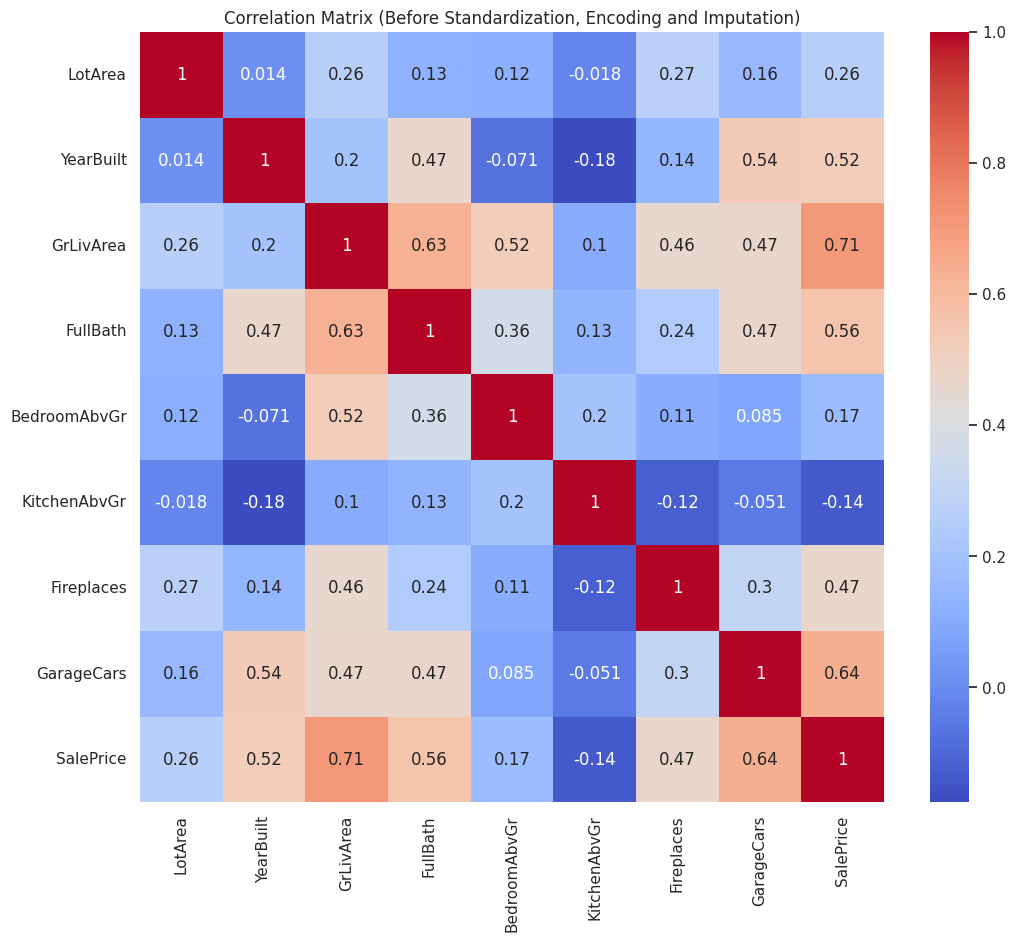

In [ ]:
X_scaled_df = pd.DataFrame(X_scaled, columns=housing_encoded.columns)
numeric_columns = housing.select_dtypes(include=['int64', 'float64']).columns
housing_numeric = housing[numeric_columns]

corr_before = housing_numeric.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_before, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix (Before Standardization, Encoding and Imputation)')
plt.show()

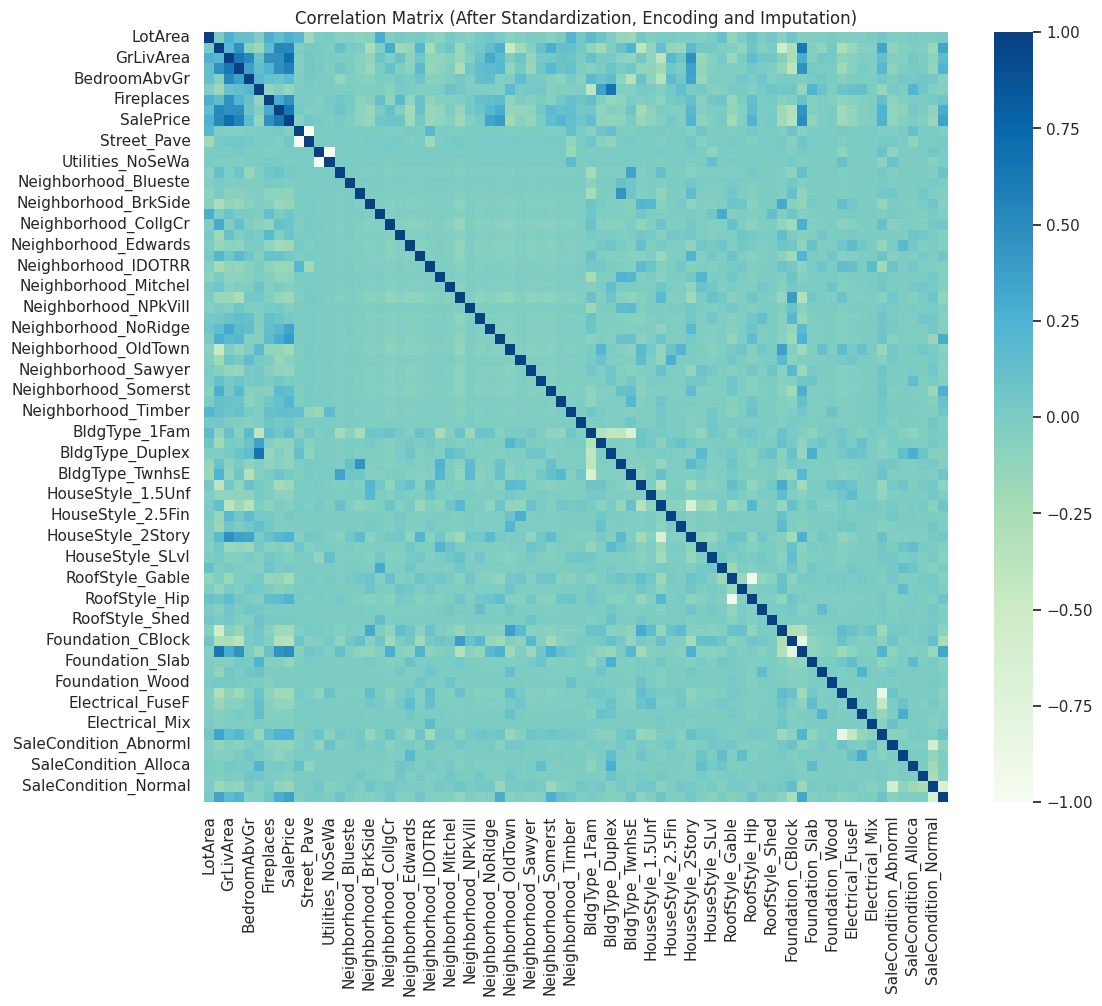

In [ ]:
X_scaled_df = pd.DataFrame(X_scaled, columns=housing_encoded.columns)

corr_after = X_scaled_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_after, cmap='GnBu')
plt.title('Correlation Matrix (After Standardization, Encoding and Imputation)')
plt.show()

In [ ]:
X = X_scaled
y = housing_encoded['SalePrice'].to_numpy()

## Features with the highest correlation with the sale price

In [ ]:
X_dataframe = pd.DataFrame(X, columns=housing_encoded.columns[:])
y_dataframe = pd.DataFrame(housing_encoded['SalePrice'], columns=['SalePrice'])

corr_matrix = pd.concat([X_dataframe, y_dataframe], axis=1).corr()

correlations = corr_matrix.iloc[-1, :-1]

print(correlations.sort_values(ascending=False).head(5))

SalePrice     1.000000
GrLivArea     0.707047
GarageCars    0.639307
FullBath      0.560112
YearBuilt     0.521700
Name: SalePrice, dtype: float64


## Train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print(" ")

print("Total number of samples:", len(X_scaled))
print("Number of samples in the training set:", len(X_train))
print("Number of samples in the testing set:", len(X_test))
print("Sum of samples in train and test:", len(X_train) + len(X_test))

test_size_example = len(X_test) / len(X_scaled)
print("Test size proportion:", test_size_example)

print('''
Checking if train and test split is successful
''')

print("Difference:", np.abs(test_size_example - 0.3))

X_train shape: (1022, 74)
X_test shape: (438, 74)
y_train shape: (1022,)
y_test shape: (438,)
 
Total number of samples: 1460
Number of samples in the training set: 1022
Number of samples in the testing set: 438
Sum of samples in train and test: 1460
Test size proportion: 0.3

Checking if train and test split is successful

Difference: 0.0


## Checking that the train and test sets do not overlap

In [ ]:
X = pd.DataFrame(X_scaled)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

if any(np.intersect1d(X_train.index, X_test.index)):
    print("The train and test data is mixed.")
else:
    print("The train and test data is not mixed.")

The train and test data is not mixed.


## Evaluation metrics
Regression has no confusion matrix, precision or recall, so the models are compared with Mean Absolute Error (MAE), Mean Squared Error (MSE) and the R² score.

# Models

## 1. Linear Regression

In [ ]:
linreg = LinearRegression().fit(X_train, y_train)
residuals = y_train - linreg.predict(X_train)
outlier_threshold = 3*np.std(residuals)
outliers = np.abs(residuals) > outlier_threshold

linreg_score = 0

if np.all(outliers):
    print("All samples are outliers, cannot fit a linear regression model")
else:
    X_train_cleaned, y_train_cleaned = X_train[~outliers], y_train[~outliers]

    linreg_cleaned = LinearRegression().fit(X_train_cleaned, y_train_cleaned)

    y_pred_cleaned = linreg_cleaned.predict(X_test)

    mse_cleaned = mean_squared_error(y_test, y_pred_cleaned)
    rmse_cleaned = np.sqrt(mse_cleaned)
    mae = mean_absolute_error(y_test, y_pred_cleaned)

    r2_score_cleaned = r2_score(y_test, y_pred_cleaned) * 100

    linreg_score = r2_score_cleaned
    linreg_mae = mae

    print(f"Mean Squared Error: {mse_cleaned:.2f}")
    print(f"Root Mean Squared Error: {rmse_cleaned:.2f}")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(" ")
    print(f"R^2 Score: {r2_score_cleaned:.6f}%")

Mean Squared Error: 9127808.41
Root Mean Squared Error: 3021.23
Mean Absolute Error: 162.90
 
R^2 Score: 99.869193%


### Overfitting or underfitting: Linear Regression

In [ ]:
train_accuracy = linreg_cleaned.score(X_train_cleaned, y_train_cleaned)

test_accuracy = linreg_cleaned.score(X_test, y_test)

print('Training accuracy:', train_accuracy)
print('Test accuracy:', test_accuracy)

Training accuracy: 1.0
Test accuracy: 0.9986919338262183


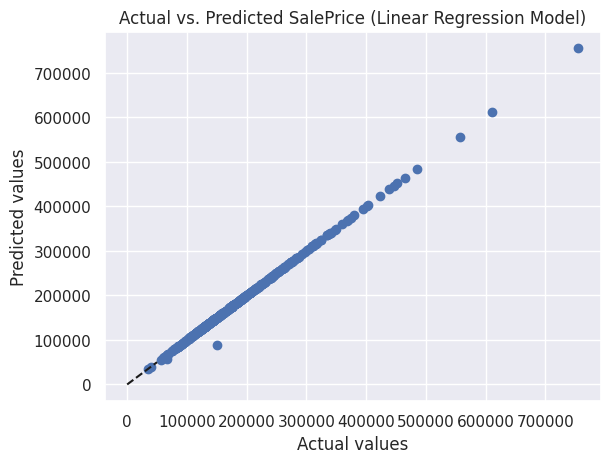

In [ ]:
plt.scatter(y_test, y_pred_cleaned)
plt.plot([0, 50000], [0, 50000], '--k')
plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs. Predicted SalePrice (Linear Regression Model)')
plt.show()

## 2. Decision Tree Regressor

In [ ]:
X = X_scaled
y = housing_encoded['SalePrice'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

decisionTreeRegressor = DecisionTreeRegressor()

decisionTreeRegressor.fit(X_train, y_train)

y_pred = decisionTreeRegressor.predict(X_test)

In [ ]:
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)

r2 = (decisionTreeRegressor.score(X_test,y_test))*100

dectree_score = r2
dectree_mae = mae

print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")
print(" ")
print(f"R^2 Score: {r2:.6f}%")

Mean Squared Error: 9945534.02
Root Mean Squared Error: 3153.65
Mean Absolute Error: 663.12
 
R^2 Score: 99.857475%


### Overfitting or underfitting: Decision Tree

In [ ]:
train_accuracy = decisionTreeRegressor.score(X_train, y_train)
test_accuracy = decisionTreeRegressor.score(X_test, y_test)

print('Training accuracy:', train_accuracy)
print('Test accuracy:', test_accuracy)

Training accuracy: 1.0
Test accuracy: 0.9985747491559225


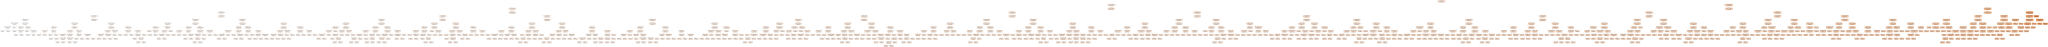

In [ ]:
dot_data = export_graphviz(decisionTreeRegressor, out_file=None,
                           feature_names=list(housing_encoded.columns),
                           filled=True, rounded=True,
                           special_characters=True)

graph = graphviz.Source(dot_data)

display(graph)

## 3. Support Vector Machine (SVM)

In [ ]:
X = housing_encoded.iloc[:, 1:8].values
y = housing_encoded.iloc[:, 8].values

scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(X)
X_train_scaled , X_test_scaled , y_train, y_test = train_test_split(X_train_scaled , y, test_size=0.3, random_state=42)

In [ ]:
svm_model = SVR(kernel='poly', C= 1000000, coef0=0.1)

svm_model.fit(X_train_scaled, y_train)

y_pred = svm_model.predict(X_test_scaled)

neg_preds = []

for pred in y_pred:
    if pred < 0:
        neg_preds.append(pred)
if len(neg_preds) > 0:
    print("Negative predicted values:", neg_preds)
else:
    print("No negative predicted values")

min_pred = min(y_pred)
max_pred = max(y_pred)
print("Minimum predicted value:", min_pred)
print("Maximum predicted value:", max_pred)

No negative predicted values
Minimum predicted value: 10629.97083834937
Maximum predicted value: 720026.0847457999


In [ ]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)*100

svm_score = r2
svm_mae = mae

print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")
print(" ")
print(f"R^2 score: {r2:.2f}%")

Mean Squared Error: 1203696403.34
Root Mean Squared Error: 34694.33
Mean Absolute Error: 24008.21
 
R^2 score: 82.75%


### Overfitting or underfitting: SVM

In [ ]:
train_accuracy = svm_model.score(X_train_scaled, y_train)
test_accuracy = svm_model.score(X_test_scaled, y_test)

print('Training accuracy:', train_accuracy)
print('Test accuracy:', test_accuracy)

Training accuracy: 0.8561085509769497
Test accuracy: 0.8275035497412019


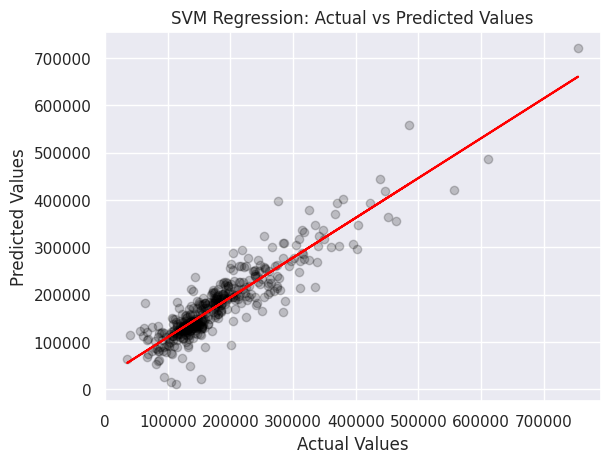

In [ ]:
plt.scatter(y_test, y_pred, color='black', alpha=0.2)

coefficients = np.polyfit(y_test, y_pred, 1)
polynomial = np.poly1d(coefficients)
plt.plot(y_test, polynomial(y_test), color='red')

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('SVM Regression: Actual vs Predicted Values')
plt.show()

# Output and comparative analysis

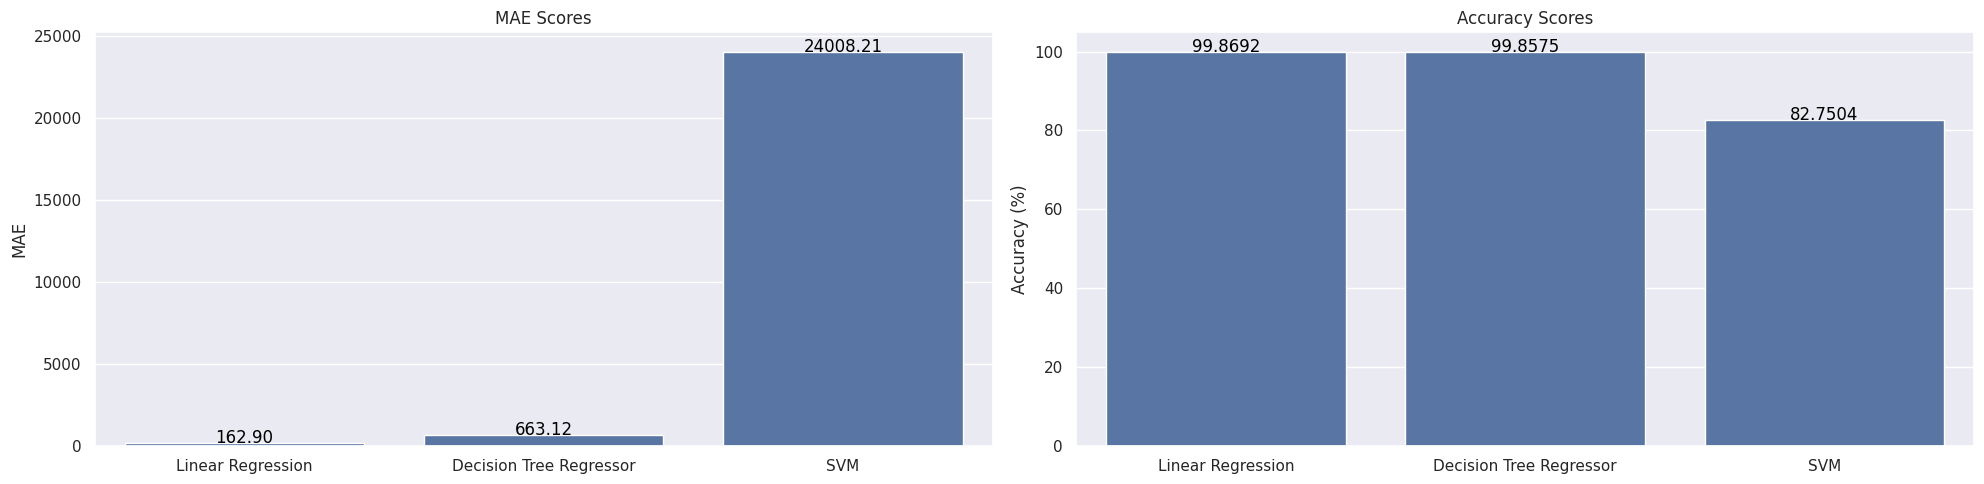

In [ ]:
models = ['Linear Regression','Decision Tree Regressor', 'SVM']
mae_scores = [linreg_mae, dectree_mae, svm_mae]
accuracy_scores = [linreg_score, dectree_score, svm_score]

sns.set(style="darkgrid")

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(20, 5))

sns.barplot(x=models, y=mae_scores, ax=axs[0])
axs[0].set_title('MAE Scores')
axs[0].set_ylabel('MAE')

for i, v in enumerate(mae_scores):
    axs[0].text(i, v, f"{v:.2f}", color='black', ha="center")


sns.barplot(x=models, y=accuracy_scores, ax=axs[1])
axs[1].set_title('Accuracy Scores')
axs[1].set_ylabel('Accuracy (%)')

for i, v in enumerate(accuracy_scores):
    axs[1].text(i, v, f"{v:.4f}", color='black', ha="center")

fig.tight_layout()
plt.show()

In [ ]:
print(f'''The models prediction accuracy are as follows:

Linear Regression: {linreg_score:.4f}%
Decision Tree Regressor: {dectree_score:.4f}%
Support Machine Vector: {svm_score:.4f}%
''')

The models prediction accuracy are as follows:

Linear Regression: 99.8692%
Decision Tree Regressor: 99.8575%
Support Machine Vector: 82.7504%

